In [1]:
import pandas as pd
from load_results import format
df_predictability = pd.read_parquet("./results/rank_predictability_merged")



df_predictability = df_predictability.assign(
    score_name="pw_acc",
    score=df_predictability["acc"],
    k=-1,           
    normalize=False    
)[[
    "Experiment",
    "Rep_A",
    "Rep_B",
    "score_name",
    "score",
    "k",
    "normalize",
    "model",
    "train_dataset",
    "train_dataset_split",
    "test_dataset",
    "test_dataset_split",
    "selection_strategy_name_a",
    "selection_strategy_name_b"
]]




df_similarity = pd.read_parquet("./results/similarity_merged")

df = pd.concat([df_predictability, df_similarity])

In [2]:

df = format(df)

In [3]:
df.groupby(["Rep_A", "Rep_B"]).mean(numeric_only=True)

score    k  \
Rep_A                      Rep_B                                            
$r^{L2}_{\nabla f} {harm}$ $r^{L2}_{\nabla f} {harm}$       0.999640 -1.0   
                           $r^{L2}_{\nabla f} {help}$       0.255400 -1.0   
                           $r^{L2}_{\nabla f} {least inf}$  0.548758 -1.0   
                           $r^{L2}_{\nabla f} {most inf}$   0.475289 -1.0   
                           $r^{id_{X}}_{\nabla f} {harm}$   0.612016 -1.0   
...                                                              ...  ...   
qwen                       $r_{{attn}}$                     0.345834 -1.0   
                           $r_{{mp}}$                       0.484829 -1.0   
                           $r_{{repsim}}$                   0.396296 -1.0   
                           nemot                            0.609335 -1.0   
                           qwen                             1.000000 -1.0   

                                                            normalize  
Rep_A                      Rep_B                                       
$r^{L2}_{\nabla f} {harm}$ $r^{L2}_{\nabla f} {harm}$        0.000000  
                           $r^{L2}_{\nabla f} {help}$        0.000000  
                           $r^{L2}_{\nabla f} {least inf}$   0.000000  
                           $r^{L2}_{\nabla f} {most inf}$    0.000000  
                           $r^{id_{X}}_{\nabla f} {harm}$    0.000000  
...                                                               ...  
qwen                       $r_{{attn}}$                      0.222222  
                           $r_{{mp}}$                        0.222222  
                           $r_{{repsim}}$                    0.222222  
                           nemot                             0.222930  
                           qwen                              0.000000  

[367 rows x 3 columns]

most_influential
all


KeyError: 'Column not found: acc'

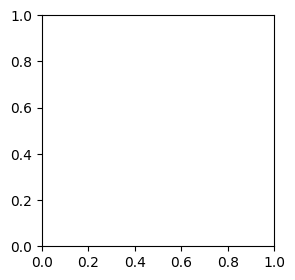

In [4]:
import matplotlib.style as mplstyle
mplstyle.use('fast')
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from load_results import load, format
import matplotlib.pyplot as plt

import matplotlib.cm as cm
import numpy as np
import os
import pandas as pd
from sklearn.manifold import MDS
from scipy.linalg import orthogonal_procrustes
import math
import regex as re
import numpy as np
import numpy as np
import numpy as np
from adjustText import adjust_text
def rgba_to_hex(rgba):
    return '#{:02x}{:02x}{:02x}'.format(
        int(rgba[0]*255),
        int(rgba[1]*255),
        int(rgba[2]*255)
    )

def plot_mds_and_heatmaps(df_, score_name, col_col=None, save_dir="figures", main_fontsize=8, filter_fn=lambda df: df):
    os.makedirs(save_dir, exist_ok=True)
    df = filter_fn(df_)
    nodes = sorted(pd.unique(df[["Rep_A", "Rep_B"]].values.ravel()))
    idx = {n: i for i, n in enumerate(nodes)}
    n = len(nodes)
    cmap = plt.get_cmap("tab20", n)
    colors = {node: cmap(i) for i, node in enumerate(nodes)}

    if col_col is None:
        experiments = ["all"]
        grouped_experiments = [("all", df)]
    else:
        experiments = df[col_col].dropna().unique()
        grouped_experiments = list(df.groupby(col_col))
        
        
    

    n_exp = len(experiments)
    max_cols = 4
    ncols = min(max_cols, n_exp)
    nrows = math.ceil(n_exp / ncols)
    square_size = 3
    
    filename_base = "_".join([col_col if col_col else "all"])# + [f"{k}={v}" for k, v in df.items()])
    filename_base = re.sub(r"[#$%&{}^~\\]", "", filename_base)
    filename_base = re.sub(r"[\s:/<>?|]+", "_", filename_base).lower()
    print(filename_base)
    

    fig_hm, axes_hm = plt.subplots(
        nrows, ncols,
        figsize=(square_size * ncols, square_size * nrows),
        squeeze=False,
        gridspec_kw={"wspace": 0.3, "hspace": 0.3},
    )
    axes_hm_flat = axes_hm.flatten()

    for ax, (exp, df_exp) in zip(axes_hm_flat, grouped_experiments):
        df_tmp = df_exp.copy()
        df_tmp[["Rep_A", "Rep_B"]] = np.sort(df_tmp[["Rep_A", "Rep_B"]], axis=1)
        df_agg = df_tmp.groupby(["Rep_A", "Rep_B"], as_index=False)[score_name].mean()

        adj = np.full((n, n), np.nan)
        np.fill_diagonal(adj, 1.0)
        for _, r in df_agg.iterrows():
            i, j = idx[r["Rep_A"]], idx[r["Rep_B"]]
            adj[i, j] = adj[j, i] = r[score_name]


        heatmap_data = pd.DataFrame(adj, index=nodes, columns=nodes)
        def fmt_custom(x):
            x_rounded = round(x, 2)
            if x_rounded == 0:
                return ".00"
            if x_rounded == int(x_rounded):
                s = str(int(x_rounded))
            else:
                s = str(x_rounded)
            if s.startswith("0.") :
                s = s[1:]
            
            return s
        sns.heatmap(
            heatmap_data,
            annot=True,
            cmap="viridis",
            vmin=0, vmax=1,
            square=True,
            cbar=False,
            ax=ax,
            annot_kws={"size": main_fontsize}
        )
        for t in ax.texts:
            val = float(t.get_text())
            t.set_text(fmt_custom(val))
        
        # # Now color each label individually
        for label in ax.get_xticklabels():
            node = label.get_text()
            label.set_color(rgba_to_hex(colors[node]))

        for label in ax.get_yticklabels():
            node = label.get_text()
            label.set_color(rgba_to_hex(colors[node]))
        if col_col:
            ax.set(title=exp.replace("_",""))
            ax.title.set_fontsize(main_fontsize+4)

    for ax in axes_hm_flat[len(grouped_experiments):]:
        ax.axis("off")
        
    
    plt.tight_layout()
    plt.show()


for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    print(selection_strategy)
    plot_mds_and_heatmaps(
        df,
        "acc",
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )
    break

most_influential
all


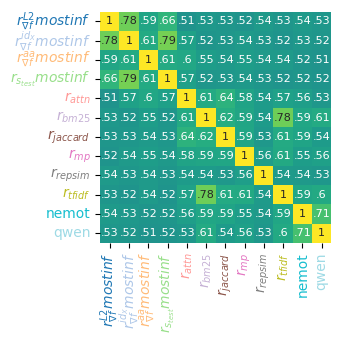

In [ ]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    print(selection_strategy)
    plot_mds_and_heatmaps(
        df,
        "acc_iso",
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )
    break